# BAN 612 Lecture 1 Demo Notebook

**From raw data to trustworthy evidence**

This notebook is designed for the first lecture. It demonstrates a compact Pandas refresher and the mindset of inspection, validation, cleaning, summarization, merging, and careful interpretation.

## 0. Setup

We begin with the standard data-analysis libraries. The data used in this notebook are small and synthetic so students can inspect every step.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Create a messy orders dataset

This dataset intentionally contains issues that look simple but are common in real projects.

In [2]:
orders_raw = pd.DataFrame({
    "order_id": [101, 102, 103, 104, 105, 105, 106, 107, 108],
    "customer_id": ["C001", "C002", "C001", "C003", "C004", "C004", "C005", "C006", "C999"],
    "order_date": ["2026-08-01", "8/2/2026", "2026/08/03", "Aug 4 2026", "2026-08-05", "2026-08-05", "not available", "2026-08-07", "2026-08-08"],
    "amount": ["$125.50", "$89.99", "$250.00", "", "$1,200.00", "$1,200.00", "-10", "$45.75", "$300.00"],
    "channel": ["Online", "Store", "online", "STORE ", "Online", "Online", "Store", "App", "Online"],
    "state": ["CA", "ca", "California", "NV", "CA", "CA", "CA", "", "CA"]
})
orders_raw

,order_id,customer_id,order_date,amount,channel,state
0,101,C001,2026-08-01,$125.50,Online,CA
1,102,C002,8/2/2026,$89.99,Store,ca
2,103,C001,2026/08/03,$250.00,online,California
3,104,C003,Aug 4 2026,,STORE,NV
4,105,C004,2026-08-05,"$1,200.00",Online,CA
5,105,C004,2026-08-05,"$1,200.00",Online,CA
6,106,C005,not available,-10,Store,CA
7,107,C006,2026-08-07,$45.75,App,
8,108,C999,2026-08-08,$300.00,Online,CA


## 2. Inspect before analyzing

A successful import does not mean the data are valid. Start by inspecting rows, columns, data types, missingness, and duplicates. The first inspection should be fast and systematic. Do not begin cleaning until you know what the dataset contains.

In [3]:
orders_raw.shape

(9, 6)

In [4]:
orders_raw.head()

,order_id,customer_id,order_date,amount,channel,state
0,101,C001,2026-08-01,$125.50,Online,CA
1,102,C002,8/2/2026,$89.99,Store,ca
2,103,C001,2026/08/03,$250.00,online,California
3,104,C003,Aug 4 2026,,STORE,NV
4,105,C004,2026-08-05,"$1,200.00",Online,CA


In [5]:
orders_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   order_id     9 non-null      int64
 1   customer_id  9 non-null      str  
 2   order_date   9 non-null      str  
 3   amount       9 non-null      str  
 4   channel      9 non-null      str  
 5   state        9 non-null      str  
dtypes: int64(1), str(5)
memory usage: 818.0 bytes


In [6]:
orders_raw.describe(include="all")

,order_id,customer_id,order_date,amount,channel,state
count,9.00,9,9,9,9,9
unique,NaN,7,8,8,5,5
top,NaN,C001,2026-08-05,"$1,200.00",Online,CA
freq,NaN,2,2,2,4,5
mean,104.56,NaN,NaN,NaN,NaN,NaN
std,2.30,NaN,NaN,NaN,NaN,NaN
min,101.00,NaN,NaN,NaN,NaN,NaN
25%,103.00,NaN,NaN,NaN,NaN,NaN
50%,105.00,NaN,NaN,NaN,NaN,NaN
75%,106.00,NaN,NaN,NaN,NaN,NaN


In [7]:
orders_raw.isna().sum()

order_id       0
customer_id    0
order_date     0
amount         0
channel        0
state          0
dtype: int64

In [8]:
orders_raw.duplicated().sum()

np.int64(1)

### Discussion prompt

What is the unit of observation? What should one row represent? What would be risky about summing `amount` immediately?

## 3. Clean obvious formatting problems

We create a clean copy instead of overwriting the raw data.

In [9]:
orders = orders_raw.copy()

# Clean amount: remove dollar signs and commas, then convert to numeric
orders["amount_clean"] = (orders["amount"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .replace("", np.nan)
)
orders["amount_clean"] = pd.to_numeric(orders["amount_clean"], errors="coerce")

# Standardize channel and state fields
orders["channel_clean"] = orders["channel"].str.strip().str.title()
orders["state_clean"] = orders["state"].str.strip().str.upper()
orders.loc[orders["state_clean"] == "CALIFORNIA", "state_clean"] = "CA"
orders.loc[orders["state_clean"] == "", "state_clean"] = np.nan

# Parse dates
orders["order_date_clean"] = pd.to_datetime(orders["order_date"], errors="coerce")

orders

,order_id,customer_id,order_date,amount,channel,state,amount_clean,channel_clean,state_clean,order_date_clean
0,101,C001,2026-08-01,$125.50,Online,CA,125.50,Online,CA,2026-08-01
1,102,C002,8/2/2026,$89.99,Store,ca,89.99,Store,CA,NaT
2,103,C001,2026/08/03,$250.00,online,California,250.00,Online,CA,NaT
3,104,C003,Aug 4 2026,,STORE,NV,NaN,Store,NV,NaT
4,105,C004,2026-08-05,"$1,200.00",Online,CA,"1,200.00",Online,CA,2026-08-05
5,105,C004,2026-08-05,"$1,200.00",Online,CA,"1,200.00",Online,CA,2026-08-05
6,106,C005,not available,-10,Store,CA,-10.00,Store,CA,NaT
7,107,C006,2026-08-07,$45.75,App,,45.75,App,NaN,2026-08-07
8,108,C999,2026-08-08,$300.00,Online,CA,300.00,Online,CA,2026-08-08


## 4. Validate business rules

Cleaning does not mean automatically fixing every value. Some values should be flagged for review.

In [10]:
validation_flags = pd.DataFrame({
    "duplicate_order_id": orders.duplicated(subset=["order_id"], keep=False),
    "missing_amount": orders["amount_clean"].isna(),
    "negative_amount": orders["amount_clean"] < 0,
    "missing_date": orders["order_date_clean"].isna(),
    "missing_state": orders["state_clean"].isna()
})
validation_flags

,duplicate_order_id,missing_amount,negative_amount,missing_date,missing_state
0,False,False,False,False,False
1,False,False,False,True,False
2,False,False,False,True,False
3,False,True,False,True,False
4,True,False,False,False,False
5,True,False,False,False,False
6,False,False,True,True,False
7,False,False,False,False,True
8,False,False,False,False,False


In [11]:
orders_with_flags = pd.concat([orders, validation_flags], axis=1)
orders_with_flags.loc[validation_flags.any(axis=1), ["order_id", "customer_id", "amount", "amount_clean", "order_date", "order_date_clean", "channel", "state", *validation_flags.columns]]

,order_id,customer_id,amount,amount_clean,order_date,order_date_clean,channel,state,duplicate_order_id,missing_amount,negative_amount,missing_date,missing_state
1,102,C002,$89.99,89.99,8/2/2026,NaT,Store,ca,False,False,False,True,False
2,103,C001,$250.00,250.00,2026/08/03,NaT,online,California,False,False,False,True,False
3,104,C003,,NaN,Aug 4 2026,NaT,STORE,NV,False,True,False,True,False
4,105,C004,"$1,200.00","1,200.00",2026-08-05,2026-08-05,Online,CA,True,False,False,False,False
5,105,C004,"$1,200.00","1,200.00",2026-08-05,2026-08-05,Online,CA,True,False,False,False,False
6,106,C005,-10,-10.00,not available,NaT,Store,CA,False,False,True,True,False
7,107,C006,$45.75,45.75,2026-08-07,2026-08-07,App,,False,False,False,False,True


### Discussion prompt

Which issues can be corrected confidently? Which should be flagged rather than changed?

## 5. Summarize after cleaning

Now we can compute simple descriptive summaries, but we still need to acknowledge flagged data.

In [12]:
valid_orders = orders_with_flags[~orders_with_flags[["missing_amount", "negative_amount", "missing_date"]].any(axis=1)].copy()
valid_orders

,order_id,customer_id,order_date,amount,channel,state,amount_clean,channel_clean,state_clean,order_date_clean,duplicate_order_id,missing_amount,negative_amount,missing_date,missing_state
0,101,C001,2026-08-01,$125.50,Online,CA,125.50,Online,CA,2026-08-01,False,False,False,False,False
4,105,C004,2026-08-05,"$1,200.00",Online,CA,"1,200.00",Online,CA,2026-08-05,True,False,False,False,False
5,105,C004,2026-08-05,"$1,200.00",Online,CA,"1,200.00",Online,CA,2026-08-05,True,False,False,False,False
7,107,C006,2026-08-07,$45.75,App,,45.75,App,NaN,2026-08-07,False,False,False,False,True
8,108,C999,2026-08-08,$300.00,Online,CA,300.00,Online,CA,2026-08-08,False,False,False,False,False


In [13]:
channel_summary = (valid_orders
    .groupby("channel_clean")
    .agg(n_orders=("order_id", "count"),
         total_sales=("amount_clean", "sum"),
         avg_order_value=("amount_clean", "mean"))
    .reset_index()
)
channel_summary

,channel_clean,n_orders,total_sales,avg_order_value
0,App,1,45.75,45.75
1,Online,4,"2,825.50",706.38


## 6. Visualize with a question in mind

The chart below answers: Which channel produced the highest total sales in the cleaned subset?

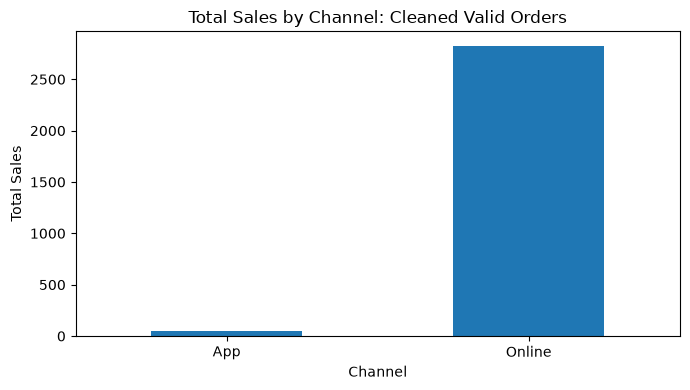

In [14]:
ax = channel_summary.plot(kind="bar", x="channel_clean", y="total_sales", legend=False, figsize=(7,4))
ax.set_title("Total Sales by Channel: Cleaned Valid Orders")
ax.set_xlabel("Channel")
ax.set_ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

### Interpretation caution

A chart can be technically correct but still incomplete. Here, Online sales are high partly because one large duplicate order is present in the raw data. We need to decide how duplicate order IDs should be handled.

## 7. Customer table and merge validation

Merging is one of the most common sources of errors. We use `validate=` to state the relationship we expect.

In [15]:
customers = pd.DataFrame({
    "customer_id": ["C001", "C002", "C003", "C004", "C005", "C006"],
    "segment": ["Loyal", "New", "At Risk", "Loyal", "New", "At Risk"],
    "signup_year": [2020, 2026, 2025, 2019, 2026, 2024]
})
customers

,customer_id,segment,signup_year
0,C001,Loyal,2020
1,C002,New,2026
2,C003,At Risk,2025
3,C004,Loyal,2019
4,C005,New,2026
5,C006,At Risk,2024


In [16]:
merged = orders.merge(customers, on="customer_id", how="left", validate="many_to_one", indicator=True)
merged[["order_id", "customer_id", "segment", "_merge"]]

,order_id,customer_id,segment,_merge
0,101,C001,Loyal,both
1,102,C002,New,both
2,103,C001,Loyal,both
3,104,C003,At Risk,both
4,105,C004,Loyal,both
5,105,C004,Loyal,both
6,106,C005,New,both
7,107,C006,At Risk,both
8,108,C999,NaN,left_only


In [17]:
merged["_merge"].value_counts()

_merge
both          8
left_only     1
right_only    0
Name: count, dtype: int64

### Discussion prompt

The customer ID `C999` does not match the customer table. What are possible explanations? Should it be dropped?

## 8. Safe versus unsafe claims

Use this final section to reinforce the claim ladder.

In [18]:
segment_summary = (merged
    .dropna(subset=["amount_clean"])
    .groupby("segment", dropna=False)
    .agg(n_orders=("order_id", "count"),
         avg_amount=("amount_clean", "mean"),
         total_sales=("amount_clean", "sum"))
    .reset_index()
)
segment_summary

,segment,n_orders,avg_amount,total_sales
0,At Risk,1,45.75,45.75
1,Loyal,4,693.88,"2,775.50"
2,New,2,39.99,79.99
3,NaN,1,300.00,300.00


**Safe claim:** In this cleaned subset, orders from the Loyal segment have the highest total sales.

**Unsafe claim:** Being a Loyal customer causes higher sales.

To make a causal claim, we would need a stronger design than a descriptive table.

## 9. Mini-exercise

Modify the notebook to answer these questions:

1. What happens to total sales by channel if duplicate `order_id` values are removed?
2. How many orders have an invalid or missing date?
3. Which customer records failed to merge?
4. Create one chart that answers a business question.
5. Write one safe claim and one unsafe claim based on your result.